# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [3]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [4]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [5]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('east')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [6]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [7]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: south
step 1 - action: north
step 2 - action: south
step 3 - action: south
step 4 - action: east
step 5 - action: suck
step 6 - action: north
step 7 - action: north
step 8 - action: suck
step 9 - action: south
step 10 - action: suck
step 11 - action: north
step 12 - action: north
step 13 - action: east
step 14 - action: east
step 15 - action: suck
step 16 - action: south
step 17 - action: east
step 18 - action: north
step 19 - action: east


4

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [8]:
import numpy as np

def environment(agent_function, n=5, p=0.2, max_steps=1000, verbose=False):
    # Khởi tạo môi trường: Lưới n x n, với xác suất p để một ô có bụi
    grid = np.random.choice([False, True], size=(n, n), p=[1-p, p])
    
    # Khởi tạo vị trí ngẫu nhiên ban đầu của robot
    pos = np.random.randint(0, n, size=2).tolist()
    
    # Biến đếm số bước (năng lượng đã dùng)
    steps = 0
    
    while steps < max_steps and np.sum(grid) > 0:
        dirty = grid[pos[0], pos[1]]
        bumpers = {
            "north": pos[0] == 0,
            "south": pos[0] == n - 1,
            "west": pos[1] == 0,
            "east": pos[1] == n - 1
        }
        
        action = agent_function(bumpers, dirty)
        
        if verbose:
            print(f"Bước {steps} - Vị trí: {pos} - Có bụi: {dirty} - Hành động: {action}")
            
        if action == "north" and not bumpers["north"]: pos[0] -= 1
        elif action == "south" and not bumpers["south"]: pos[0] += 1
        elif action == "west" and not bumpers["west"]: pos[1] -= 1
        elif action == "east" and not bumpers["east"]: pos[1] += 1
        elif action == "suck" and dirty: grid[pos[0], pos[1]] = False
                
        steps += 1

    if verbose:
        if np.sum(grid) == 0:
            print(f"Hoàn thành dọn dẹp sau {steps} bước!")
        else:
            print(f"Hết năng lượng sau {steps} bước. Còn lại {np.sum(grid)} ô bụi.")
            
    return steps

Show that your environment works with the simple randomized agent from above.

In [9]:
# Chạy thử mô phỏng với simple_randomized_agent
print("Thử nghiệm Simple Randomized Agent:")
performance = environment(simple_randomized_agent, n=5, p=0.2, max_steps=1000, verbose=True)
print(f"Hiệu suất (số bước): {performance}")

Thử nghiệm Simple Randomized Agent:
Bước 0 - Vị trí: [2, 1] - Có bụi: False - Hành động: west
Bước 1 - Vị trí: [2, 0] - Có bụi: False - Hành động: suck
Bước 2 - Vị trí: [2, 0] - Có bụi: False - Hành động: west
Bước 3 - Vị trí: [2, 0] - Có bụi: False - Hành động: south
Bước 4 - Vị trí: [3, 0] - Có bụi: False - Hành động: suck
Bước 5 - Vị trí: [3, 0] - Có bụi: False - Hành động: south
Bước 6 - Vị trí: [4, 0] - Có bụi: False - Hành động: suck
Bước 7 - Vị trí: [4, 0] - Có bụi: False - Hành động: south
Bước 8 - Vị trí: [4, 0] - Có bụi: False - Hành động: east
Bước 9 - Vị trí: [4, 1] - Có bụi: False - Hành động: north
Bước 10 - Vị trí: [3, 1] - Có bụi: False - Hành động: west
Bước 11 - Vị trí: [3, 0] - Có bụi: False - Hành động: west
Bước 12 - Vị trí: [3, 0] - Có bụi: False - Hành động: north
Bước 13 - Vị trí: [2, 0] - Có bụi: False - Hành động: south
Bước 14 - Vị trí: [3, 0] - Có bụi: False - Hành động: suck
Bước 15 - Vị trí: [3, 0] - Có bụi: False - Hành động: suck
Bước 16 - Vị trí: [3, 0]

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [10]:
def simple_reflex_agent(bumpers, dirty):
    # Nếu có bụi thì hút
    if dirty:
        return "suck"
    
    # Lấy danh sách các hướng có thể đi (không bị đụng tường)
    possible_actions = []
    if not bumpers["north"]: possible_actions.append("north")
    if not bumpers["south"]: possible_actions.append("south")
    if not bumpers["west"]: possible_actions.append("west")
    if not bumpers["east"]: possible_actions.append("east")
    
    # Chọn ngẫu nhiên một hướng đi không bị đụng tường
    return np.random.choice(possible_actions)

Show how the agent works with your environment.

In [11]:
# Chạy thử mô phỏng với simple_reflex_agent
print("Thử nghiệm Simple Reflex Agent:")
performance = environment(simple_reflex_agent, n=5, p=0.2, max_steps=1000, verbose=True)
print(f"Hiệu suất (số bước): {performance}")

Thử nghiệm Simple Reflex Agent:
Bước 0 - Vị trí: [4, 4] - Có bụi: False - Hành động: north
Bước 1 - Vị trí: [3, 4] - Có bụi: False - Hành động: south
Bước 2 - Vị trí: [4, 4] - Có bụi: False - Hành động: north
Bước 3 - Vị trí: [3, 4] - Có bụi: False - Hành động: south
Bước 4 - Vị trí: [4, 4] - Có bụi: False - Hành động: north
Bước 5 - Vị trí: [3, 4] - Có bụi: False - Hành động: north
Bước 6 - Vị trí: [2, 4] - Có bụi: False - Hành động: west
Bước 7 - Vị trí: [2, 3] - Có bụi: False - Hành động: north
Bước 8 - Vị trí: [1, 3] - Có bụi: False - Hành động: north
Bước 9 - Vị trí: [0, 3] - Có bụi: False - Hành động: west
Bước 10 - Vị trí: [0, 2] - Có bụi: True - Hành động: suck
Bước 11 - Vị trí: [0, 2] - Có bụi: False - Hành động: west
Bước 12 - Vị trí: [0, 1] - Có bụi: False - Hành động: west
Bước 13 - Vị trí: [0, 0] - Có bụi: False - Hành động: south
Bước 14 - Vị trí: [1, 0] - Có bụi: False - Hành động: south
Bước 15 - Vị trí: [2, 0] - Có bụi: False - Hành động: south
Bước 16 - Vị trí: [3, 0]

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

In [12]:
"""
Mô tả trạng thái (State):
Agent sẽ ghi nhớ trạng thái di chuyển hiện tại để thực hiện quét theo mẫu ziczac (Boustrophedon).
- Ban đầu agent mặc định hướng về phía "east".
- Nó sẽ đi sang "east" cho đến khi đụng tường (bumpers["east"] == True).
- Sau đó nó sẽ lùi xuống "south" một bước và đổi hướng sang "west".
- Nó sẽ đi sang "west" cho đến khi đụng tường, sau đó lùi xuống "south" và đổi hướng về "east".
- Quá trình lặp lại đến khi đụng tường "south" và không thể đi tiếp, coi như đã quét xong.
State sẽ bao gồm:
- direction: Hướng đi hiện tại ("east" hoặc "west")
- move_down: Cờ đánh dấu bước tiếp theo phải đi "south" hay không.
Chúng ta sẽ lưu state dưới dạng thuộc tính của hàm để giữ được state giữa các lần gọi.
"""

'\nMô tả trạng thái (State):\nAgent sẽ ghi nhớ trạng thái di chuyển hiện tại để thực hiện quét theo mẫu ziczac (Boustrophedon).\n- Ban đầu agent mặc định hướng về phía "east".\n- Nó sẽ đi sang "east" cho đến khi đụng tường (bumpers["east"] == True).\n- Sau đó nó sẽ lùi xuống "south" một bước và đổi hướng sang "west".\n- Nó sẽ đi sang "west" cho đến khi đụng tường, sau đó lùi xuống "south" và đổi hướng về "east".\n- Quá trình lặp lại đến khi đụng tường "south" và không thể đi tiếp, coi như đã quét xong.\nState sẽ bao gồm:\n- direction: Hướng đi hiện tại ("east" hoặc "west")\n- move_down: Cờ đánh dấu bước tiếp theo phải đi "south" hay không.\nChúng ta sẽ lưu state dưới dạng thuộc tính của hàm để giữ được state giữa các lần gọi.\n'

In [13]:
def model_based_reflex_agent(bumpers, dirty):
    # Khởi tạo state tĩnh
    if not hasattr(model_based_reflex_agent, "state"):
        model_based_reflex_agent.state = {
            "finding_corner": True,
            "direction": "east",
            "move_down": False
        }
    
    state = model_based_reflex_agent.state
    
    # Ưu tiên hút bụi
    if dirty:
        return "suck"
    
    # Giai đoạn tìm góc Tây-Bắc
    if state["finding_corner"]:
        if not bumpers["north"]:
            return "north"
        if not bumpers["west"]:
            return "west"
        # Đã chạm góc Tây-Bắc
        state["finding_corner"] = False
        state["direction"] = "east"
        state["move_down"] = False
        
    # Giai đoạn quét ziczac
    if state["move_down"]:
        state["move_down"] = False
        if not bumpers["south"]:
            return "south"
        
    if state["direction"] == "east":
        if not bumpers["east"]:
            return "east"
        else:
            state["direction"] = "west"
            state["move_down"] = True
            if not bumpers["south"]:
                return "south"
    elif state["direction"] == "west":
        if not bumpers["west"]:
            return "west"
        else:
            state["direction"] = "east"
            state["move_down"] = True
            if not bumpers["south"]:
                return "south"
                
    return "north" # Default if stuck

Show how the agent works with your environment.

In [14]:
# Xóa state cũ trước khi bắt đầu mô phỏng
if hasattr(model_based_reflex_agent, "state"):
    del model_based_reflex_agent.state

print("Thử nghiệm Model-based Reflex Agent:")
performance = environment(model_based_reflex_agent, n=5, p=0.2, max_steps=1000, verbose=True)
print(f"Hiệu suất (số bước): {performance}")

Thử nghiệm Model-based Reflex Agent:
Bước 0 - Vị trí: [0, 1] - Có bụi: True - Hành động: suck
Bước 1 - Vị trí: [0, 1] - Có bụi: False - Hành động: west
Bước 2 - Vị trí: [0, 0] - Có bụi: False - Hành động: east
Bước 3 - Vị trí: [0, 1] - Có bụi: False - Hành động: east
Bước 4 - Vị trí: [0, 2] - Có bụi: True - Hành động: suck
Bước 5 - Vị trí: [0, 2] - Có bụi: False - Hành động: east
Bước 6 - Vị trí: [0, 3] - Có bụi: False - Hành động: east
Bước 7 - Vị trí: [0, 4] - Có bụi: True - Hành động: suck
Bước 8 - Vị trí: [0, 4] - Có bụi: False - Hành động: south
Bước 9 - Vị trí: [1, 4] - Có bụi: True - Hành động: suck
Bước 10 - Vị trí: [1, 4] - Có bụi: False - Hành động: south
Bước 11 - Vị trí: [2, 4] - Có bụi: False - Hành động: west
Bước 12 - Vị trí: [2, 3] - Có bụi: True - Hành động: suck
Bước 13 - Vị trí: [2, 3] - Có bụi: False - Hành động: west
Bước 14 - Vị trí: [2, 2] - Có bụi: False - Hành động: west
Bước 15 - Vị trí: [2, 1] - Có bụi: False - Hành động: west
Bước 16 - Vị trí: [2, 0] - Có bụ

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Hàm wrapper để reset state của model_based agent
def run_simulation(agent_func, size, num_runs=100, max_steps=10000):
    total_steps = 0
    for _ in range(num_runs):
        if hasattr(agent_func, "state"):
            del agent_func.state
        steps = environment(agent_func, n=size, p=0.2, max_steps=max_steps, verbose=False)
        total_steps += steps
    return total_steps / num_runs

sizes = [5, 10, 100]
agents = {
    "Random Agent": simple_randomized_agent,
    "Simple Reflex Agent": simple_reflex_agent,
    "Model-based Agent": model_based_reflex_agent
}

results = []

for size in sizes:
    # Tăng max_steps cho grid lớn
    max_steps = size * size * 10
    row = {"Grid Size": f"{size}x{size}"}
    for agent_name, agent_func in agents.items():
        print(f"Running {agent_name} on {size}x{size}...")
        avg_steps = run_simulation(agent_func, size, num_runs=100, max_steps=max_steps)
        row[agent_name] = avg_steps
    results.append(row)

df_results = pd.DataFrame(results)
print("Hoàn thành mô phỏng!")

Running Random Agent on 5x5...
Running Simple Reflex Agent on 5x5...
Running Model-based Agent on 5x5...
Running Random Agent on 10x10...
Running Simple Reflex Agent on 10x10...
Running Model-based Agent on 10x10...
Running Random Agent on 100x100...
Running Simple Reflex Agent on 100x100...
Running Model-based Agent on 100x100...
Hoàn thành mô phỏng!


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

,Grid Size,Random Agent,Simple Reflex Agent,Model-based Agent
0,5x5,232.00,86.39,202.03
1,10x10,997.81,767.23,1000.00
2,100x100,100000.00,100000.00,100000.00


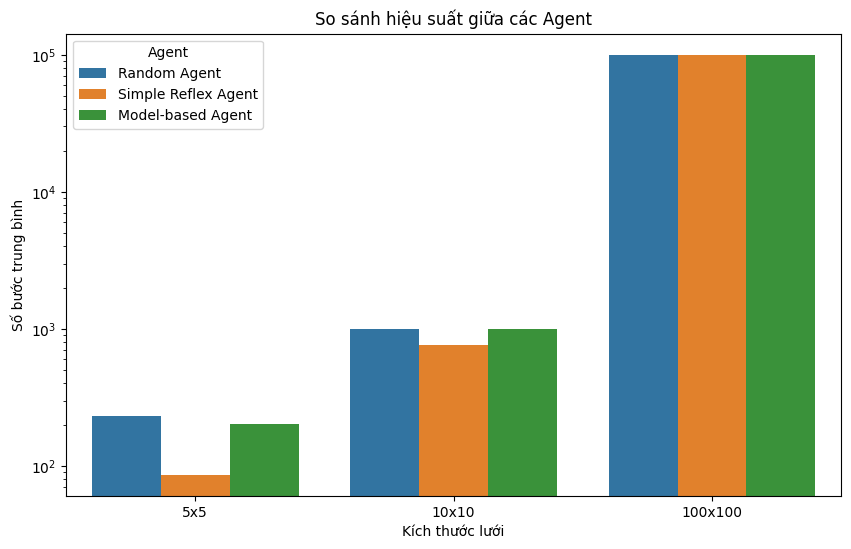

'\nThảo luận:\n- Random Agent hoạt động rất kém, đặc biệt là trên lưới lớn (100x100), số bước cần thiết thường chạm giới hạn max_steps.\n- Simple Reflex Agent tốt hơn một chút nhờ tránh được việc đâm vào tường, nhưng vẫn di chuyển ngẫu nhiên nên tốn nhiều thời gian để quét sạch không gian lớn.\n- Model-based Agent có hiệu suất vượt trội do di chuyển theo mẫu ziczac (Boustrophedon), quét qua toàn bộ lưới một cách có hệ thống, không bỏ sót và không lặp lại quá nhiều. Số bước tăng theo diện tích lưới.\n'

In [17]:
import seaborn as sns

# Hiển thị bảng kết quả
display(df_results)

# Vẽ biểu đồ
df_melted = df_results.melt(id_vars="Grid Size", var_name="Agent", value_name="Average Steps")

plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x="Grid Size", y="Average Steps", hue="Agent")
plt.title("So sánh hiệu suất giữa các Agent")
plt.ylabel("Số bước trung bình")
plt.xlabel("Kích thước lưới")
plt.yscale('log') # Dùng log scale vì 100x100 rất lớn
plt.show()

"""
Thảo luận:
- Random Agent hoạt động rất kém, đặc biệt là trên lưới lớn (100x100), số bước cần thiết thường chạm giới hạn max_steps.
- Simple Reflex Agent tốt hơn một chút nhờ tránh được việc đâm vào tường, nhưng vẫn di chuyển ngẫu nhiên nên tốn nhiều thời gian để quét sạch không gian lớn.
- Model-based Agent có hiệu suất vượt trội do di chuyển theo mẫu ziczac (Boustrophedon), quét qua toàn bộ lưới một cách có hệ thống, không bỏ sót và không lặp lại quá nhiều. Số bước tăng theo diện tích lưới.
"""

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Trả lời (Task 5):

1. **Nếu đặt trong phòng hình chữ nhật kích thước không xác định:**
   - *Random/Simple Reflex Agent:* Vẫn hoạt động bình thường, nhưng hiệu suất càng tệ nếu phòng càng rộng.
   - *Model-based Agent:* Vẫn hoạt động tốt do mô hình ziczac của nó không phụ thuộc vào kích thước phòng. Nó cứ đi tới khi đụng tường thì mới lùi và vòng lại. Tuy nhiên nó mặc định bắt đầu ở góc, nếu không bắt đầu ở góc nó sẽ cần thuật toán tìm góc trước tiên.

2. **Nếu khu vực làm sạch có hình dạng bất thường (VD: hành lang nối 2 phòng):**
   - *Random/Simple Reflex Agent:* Sẽ khó lọt qua hành lang hoặc tốn rất nhiều thời gian.
   - *Model-based Agent:* Thuật toán ziczac hiện tại sẽ thất bại khi gặp vật cản hoặc hành lang hẹp vì nó cho rằng đụng tường "nam" và "đông/tây" cùng lúc là hết phòng.

3. **Nếu có chướng ngại vật trong phòng:**
   - *Random/Simple Reflex Agent:* Ít bị ảnh hưởng (nó chỉ coi đó như bức tường và đổi hướng).
   - *Model-based Agent:* Sẽ gặp lỗi vì nó coi chướng ngại vật như bức tường biên, dẫn tới đổi hướng sớm và bỏ sót phần lớn căn phòng phía sau vật cản.

4. **Nếu cảm biến bụi sai 10% (nhiễu):**
   - Các Agent có thể hút khi không có bụi (tốn bước vô ích) hoặc không hút khi có bụi (bỏ sót bụi). Agent model-based hiện tại không quay lại nên sẽ để lại bụi trong phòng.

5. **Nếu cảm biến va chạm sai 10%:**
   - Robot sẽ cố gắng đi vào tường nhưng bị chặn, mất bước di chuyển (năng lượng) và có thể khiến State của Model-based Agent bị sai lệch (tưởng chưa đụng tường nhưng thực tế đã đụng), làm hỏng luồng ziczac.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [18]:
import numpy as np

def environment_noisy(agent_function, n=5, p=0.2, max_steps=1000, verbose=False, noise=0.1):
    grid = np.random.choice([False, True], size=(n, n), p=[1-p, p])
    pos = [0, 0] # Bắt đầu ở góc cho model-based agent dễ chạy
    steps = 0
    
    while steps < max_steps and np.sum(grid) > 0:
        dirty_actual = grid[pos[0], pos[1]]
        # Nhiễu 10%
        if np.random.rand() < noise:
            dirty = not dirty_actual
        else:
            dirty = dirty_actual
            
        bumpers = {
            "north": pos[0] == 0,
            "south": pos[0] == n - 1,
            "west": pos[1] == 0,
            "east": pos[1] == n - 1
        }
        
        action = agent_function(bumpers, dirty)
        
        if action == "north" and not bumpers["north"]: pos[0] -= 1
        elif action == "south" and not bumpers["south"]: pos[0] += 1
        elif action == "west" and not bumpers["west"]: pos[1] -= 1
        elif action == "east" and not bumpers["east"]: pos[1] += 1
        elif action == "suck" and dirty_actual:
            grid[pos[0], pos[1]] = False
                
        steps += 1

    return steps, np.sum(grid)

# Cải thiện Model-based Agent:
# Giải pháp: Vì cảm biến bụi có nhiễu 10%, nếu agent chỉ phụ thuộc vào 1 lần đọc cảm biến,
# nó có thể bỏ sót bụi. Cải tiến đơn giản: hút "mù" khi vừa đến ô mới, 
# bất kể cảm biến báo gì (vì chi phí hút thường không đáng kể so với việc để lại bụi).

def model_based_reflex_agent_improved(bumpers, dirty):
    if not hasattr(model_based_reflex_agent_improved, "state"):
        model_based_reflex_agent_improved.state = {
            "direction": "east",
            "move_down": False,
            "just_moved": True # Cờ đánh dấu vừa di chuyển tới ô mới
        }
    
    state = model_based_reflex_agent_improved.state
    
    # Ưu tiên hút nếu vừa di chuyển hoặc cảm biến báo bẩn
    if state["just_moved"] or dirty:
        state["just_moved"] = False
        return "suck"
    
    # Logic di chuyển ziczac giống hệt trước
    state["just_moved"] = True
    
    if state["move_down"]:
        state["move_down"] = False
        if not bumpers["south"]:
            return "south"
        
    if state["direction"] == "east":
        if not bumpers["east"]:
            return "east"
        else:
            state["direction"] = "west"
            state["move_down"] = True
            if not bumpers["south"]:
                return "south"
    elif state["direction"] == "west":
        if not bumpers["west"]:
            return "west"
        else:
            state["direction"] = "east"
            state["move_down"] = True
            if not bumpers["south"]:
                return "south"
                
    return "north"

# Thử nghiệm
if hasattr(model_based_reflex_agent, "state"): del model_based_reflex_agent.state
print("Chạy Model-based Agent (Cũ) trên môi trường nhiễu 10%:")
steps_old, dirt_old = environment_noisy(model_based_reflex_agent, n=5, p=0.2, max_steps=1000)
print(f"Số bước: {steps_old}, Bụi còn sót: {dirt_old}")

if hasattr(model_based_reflex_agent_improved, "state"): del model_based_reflex_agent_improved.state
print("Chạy Model-based Agent (Cải tiến) trên môi trường nhiễu 10%:")
steps_new, dirt_new = environment_noisy(model_based_reflex_agent_improved, n=5, p=0.2, max_steps=1000)
print(f"Số bước: {steps_new}, Bụi còn sót: {dirt_new}")

Chạy Model-based Agent (Cũ) trên môi trường nhiễu 10%:
Số bước: 1000, Bụi còn sót: 2
Chạy Model-based Agent (Cải tiến) trên môi trường nhiễu 10%:
Số bước: 27, Bụi còn sót: 0


## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [19]:
# Your ideas/code